# 07-2. 장기 메모리: Store로 스레드 간 정보 공유

**시나리오:** AI 학습 튜터 챗봇을 만든다고 하자.  
학습자가 "실습 코드 예제로 설명해 주세요"처럼 선호를 한 번 말해 두면, 다음에 대화창을 새로 열어도(= 새로운 스레드) 챗봇이 그 선호를 기억해서 답변 방식을 맞춰야 한다.   
동시에 다른 학습자의 정보와는 섞이면 안 된다.   
이런 "대화(스레드)를 넘어 남아야 하는 정보"가 바로 장기 메모리이고, 이 노트북은 `Store`로 이를 구현한다.

## 학습 목표
- `InMemoryStore`에 학습자별 선호 정보를 저장하고 조회한다.
- 학습자가 새 대화(다른 `thread_id`)를 시작해도 같은 사용자의 정보를 이어서 읽고, 다른 학습자의 정보와는 구분됨을 확인한다.
- Checkpointer(대화 하나의 State)와 Store(여러 대화에 걸친 정보)의 역할을 코드 수준에서 비교한다.

## 핵심 개념과 실행 전 예측
챗봇 대화창을 새로 열면(= 새 `thread_id`) Checkpoint는 이전 대화의 State를 들고 오지 않는다. 하지만 Store는 `thread_id`와 무관하게 **같은 사용자(`user_id`)**의 정보를 계속 들고 있다. 여기서는 `("preferences", user_id)`를 저장 위치(namespace)로 사용한다. 학습자 A가 첫 대화에서 선호를 말해 저장한 뒤, 완전히 새로운 대화를 시작해 다시 물으면 챗봇은 그 선호를 기억해 낼까? 다른 학습자가 묻는다면 어떨까?

`InMemoryStore`의 "장기"는 **스레드 간 사용 범위**를 뜻한다. 저장 매체는 메모리이므로 Python 프로세스가 끝나면(= 서버를 재시작하면) 데이터는 사라진다. 이 실습은 임베딩이나 의미 검색 없이 키로 조회한다.

In [15]:
from dataclasses import dataclass
from pydantic import BaseModel
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import START, END, StateGraph
from langgraph.runtime import Runtime
from langgraph.store.memory import InMemoryStore

# 매 invoke()마다 오가는 값. Store(장기 메모리)와 헷갈리지 않도록 이름에 "Memory"를 넣지 않았다.
class ActionState(BaseModel):
    action: str       # "save"(저장) 또는 "read"(조회)
    preference: str   # 저장할 값. "read"일 때는 빈 문자열
    result: str       # Node가 채워 넣는 결과 문자열

# graph.invoke(..., context=...)로 전달되는 값. config의 thread_id(어느 실행인가)와는
# 다른 축인 user_id(누구의 정보인가)를 구분하는 것이 이번 실습의 핵심이다.
@dataclass
class UserContext:
    user_id: str

store = InMemoryStore()        # 장기 메모리: user_id(namespace) 단위로 정보를 보관한다.
checkpointer = InMemorySaver() # 단기 메모리: thread_id 단위로 State 스냅샷을 보관한다(07-1 참고).

def action_node(state: ActionState, runtime: Runtime[UserContext]) -> dict:
    namespace = ("preferences", runtime.context.user_id)  # Store 안의 저장 위치("폴더 경로")
    key = "learning_style"                                 # namespace 안의 세부 항목 이름

    if state.action == "save":
        # Store에 저장한다. runtime.store.put()은 namespace, key, value를 받아서 저장한다.
        runtime.store.put(namespace, key, {"value": state.preference})  
        return {"result": "선호 저장 완료"}
    if state.action == "read":
        # Store에서 읽어온다. runtime.store.get()은 namespace, key를 받아서 Item을 반환한다. 없으면 None, 있으면 Item(.value가 저장한 dict)
        item = runtime.store.get(namespace, key)  # 없으면 None, 있으면 Item(.value가 저장한 dict)
        return {"result": item.value["value"] if item else "저장된 선호 없음"}
    raise ValueError("action은 save 또는 read여야 한다")

# StateGraph 정의
builder = StateGraph(ActionState, context_schema=UserContext) # StateGraph의 상태와 context의 스키마를 지정한다.
builder.add_node("action", action_node)
builder.add_edge(START, "action")
builder.add_edge("action", END)

# Node 안에서 runtime.store를 쓰려면 store를, 스레드별 State 비교를 위해 checkpointer를 함께 등록한다.
graph = builder.compile(checkpointer=checkpointer, store=store)

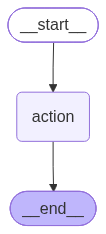

In [16]:
from common.utils import visualize_graph
visualize_graph(graph)

## 실습 A. 첫 대화에서 선호 저장
학습자 A가 챗봇과의 **첫 대화**에서 "실습 코드 예제로 설명해 주세요"라고 선호를 말한다. `context`는 "누구의 정보인가"(= 어떤 학습자인가)를 지정하고, `thread_id`는 "어느 대화인가"(= 어느 실행 State인가)를 지정한다.

In [17]:
# 장기 메모리: Store는 thread_id와 무관하게 같은 user_id면 어떤 스레드에서든 값을 읽을 수 있음.
learner_a = UserContext(user_id="learner-a")

# 단기 메모리: Checkpointer는 thread_id 단위로 State 스냅샷을 보관한다.
thread_a1 = {"configurable": {"thread_id": "learner-a-thread-1"}}

# config=thread_a1은 Checkpoint(어느 실행), context=learner_a는 Store(누구의 정보)를 가리킨다.
saved = graph.invoke(
    {"action": "save", "preference": "실습 코드 예제로 설명해 주세요", "result": ""},
    config=thread_a1,    # Checkpoint(어느 실행)
    context=learner_a,   # Store(누구의 정보)
)

In [18]:
# 단기기억 결과 출력
print("스레드 1번 결과 :", saved)

스레드 1번 결과 : {'action': 'save', 'preference': '실습 코드 예제로 설명해 주세요', 'result': '선호 저장 완료'}


In [19]:
store.get(("preferences", "learner-a"), "learning_style")

Item(namespace=['preferences', 'learner-a'], key='learning_style', value={'value': '실습 코드 예제로 설명해 주세요'}, created_at='2026-10-14T02:40:04.092426+00:00', updated_at='2026-10-14T02:40:04.092427+00:00')

In [20]:
# 장기기억 결과 출력
print("Store 항목:", store.get(("preferences", "learner-a"), "learning_style").value)

Store 항목: {'value': '실습 코드 예제로 설명해 주세요'}


In [21]:
print("스레드 1 Checkpoint:", graph.get_state(thread_a1).values)

assert saved["result"] == "선호 저장 완료"
assert store.get(("preferences", "learner-a"), "learning_style").value["value"] == "실습 코드 예제로 설명해 주세요"

스레드 1 Checkpoint: {'action': 'save', 'preference': '실습 코드 예제로 설명해 주세요', 'result': '선호 저장 완료'}


## 실습 B. 새 대화에서 같은 학습자의 선호 다시 꺼내기
학습자 A가 대화창을 닫고 **새 대화**를 시작한다(= 새 `thread_id`). 이번 대화의 State에는 이전 `preference`가 들어 있지 않다. 하지만 Store에는 학습자 A의 선호가 남아 있으므로, 챗봇이 그 선호를 다시 꺼내 쓸 수 있는지 확인한다. 실행 전에 `result`를 예상한다.

In [22]:
# thread_id는 새로 만들었지만 context(user_id)는 그대로라 Store 값을 그대로 읽는다.
thread_a2 = {"configurable": {"thread_id": "learner-a-thread-2"}}
read_a = graph.invoke(
    {"action": "read", "preference": "", "result": ""},
    config=thread_a2,
    context=learner_a,
)

In [23]:
print("새 스레드 결과:", read_a)

새 스레드 결과: {'action': 'read', 'preference': '', 'result': '실습 코드 예제로 설명해 주세요'}


In [24]:
print("새 스레드 Checkpoint:", graph.get_state(thread_a2).values)

새 스레드 Checkpoint: {'action': 'read', 'preference': '', 'result': '실습 코드 예제로 설명해 주세요'}


In [25]:
assert read_a["result"] == "실습 코드 예제로 설명해 주세요"
assert read_a["preference"] == ""  # 이번 스레드의 입력에는 선호 값이 없다.

## 실습 C. 다른 학습자와 분리
이번에는 학습자 B가 같은 챗봇과 새 대화를 시작한다. B는 A와 다른 `user_id`를 쓰므로 Store 안에서도 다른 namespace를 쓴다. `thread_id`뿐 아니라 `user_id`도 달라지면, 챗봇이 학습자 A의 선호를 B에게 잘못 적용하지 않는지 확인한다.

In [26]:
# user_id까지 달라지므로 namespace도 달라져 A의 정보에 접근할 수 없다.
learner_b = UserContext(user_id="learner-b")
thread_b1 = {"configurable": {"thread_id": "learner-b-thread-1"}}
read_b = graph.invoke(
    {"action": "read", "preference": "", "result": ""},
    config=thread_b1,
    context=learner_b,
)

In [27]:
print("다른 사용자 결과:", read_b)

다른 사용자 결과: {'action': 'read', 'preference': '', 'result': '저장된 선호 없음'}


In [12]:
print("학습자 A의 Store 항목:", [item.value for item in store.search(("preferences", "learner-a"))])

학습자 A의 Store 항목: [{'value': '실습 코드 예제로 설명해 주세요'}]


In [13]:
print("학습자 B의 Store 항목:", [item.value for item in store.search(("preferences", "learner-b"))])

학습자 B의 Store 항목: []


In [49]:
assert read_b["result"] == "저장된 선호 없음"
assert len(store.search(("preferences", "learner-a"))) == 1
assert len(store.search(("preferences", "learner-b"))) == 0

`search(namespace)`는 여기서 해당 namespace의 항목을 나열한다. 즉 "학습자 A의 기록만 모아서 보여 달라" 같은 조회다. 자연어 질문으로 유사한 기억을 찾는 **의미 검색**(예: "이 학습자가 선호하는 설명 방식이 뭐였지?"를 임베딩으로 찾는 것)은 추가 설정이 필요하며 이 기초 실습에서는 다루지 않는다.

## 이해 확인
1. 스레드 2의 `preference`는 빈 문자열인데 `result`에 선호가 나타나는 이유는 무엇인가?  
   **해설:** Node가 사용자 A의 namespace에서 Store 항목을 조회했기 때문이다.
2. `InMemoryStore`를 사용하면 Python 재시작 후에도 정보가 남는가?  
   **해설:** 아니다. 스레드 간 공유는 가능하지만 메모리 기반이므로 프로세스 종료 시 사라진다.

**핵심 정리:** Checkpointer는 `thread_id`별 실행 State, Store는 namespace별 재사용 정보를 관리한다. 사용자 식별자와 스레드 식별자는 서로 다른 역할을 한다.